# Analisis Pasar Kerja Profesi Data di Indonesia
### Riset Empiris Berbasis 430 Lowongan Kerja Glints Indonesia

Notebook ini menganalisis kondisi pasar tenaga kerja sektor data di Indonesia (Data Analyst, Data Engineer, Data Scientist, ML Engineer). Analisis dibangun di atas 430 lowongan kerja aktif dari Glints Indonesia yang telah divalidasi dan disaring secara ketat (100% berbasis di Indonesia, deduplikasi, dan pembersihan data).

---

## Ringkasan Eksekutif

Dari 430 lowongan kerja data yang dianalisis (349 di antaranya mencantumkan nominal gaji transparan):

1. **Beban Kualifikasi Entry-Level:** Lowongan tingkat pemula (<1 tahun pengalaman) mencatatkan proporsi tuntutan skill teoritis tertinggi: Python (70,6%), Statistik (58,8%), dan Machine Learning (47,1%), dengan median gaji terendah (Rp 4,2 juta). Sebaliknya, posisi Mid/Senior (>3 tahun) lebih terfokus pada integrasi sistem operasional (ETL 41,5%, Power BI/Tableau 35,1%, Cloud 27,7%) dengan median gaji Rp 9,0 – 15,0+ juta.
2. **Ketersediaan Kerja Remote:** Sebanyak 90,7% lowongan mensyaratkan kerja On-site (WFO). Opsi Full Remote hanya mencakup 3,5% dari total lowongan, namun menawarkan median gaji Rp 12,5 juta berbanding On-site Rp 7,0 juta (+78,6% premi).
3. **Kebutuhan Tech Stack Industri:** Kebutuhan industri didominasi oleh SQL (428 kemunculan) dan Excel (246 kemunculan). Kebutuhan deep learning dan framework AI spesifik (PyTorch, TensorFlow) hanya muncul pada sebagian kecil posisi riset (<30 kemunculan).
4. **Pintu Masuk Fresh Graduate:** Hanya 5,8% lowongan yang secara eksplisit menerima kandidat tanpa pengalaman (0 tahun), menegaskan pentingnya portofolio proyek terapan bagi pelamar pemula.

---

## Setup Environment & Data Loading

Pemuatan master dataset `data/processed/master_dataset_eda.csv` dan modul visualisasi terpusat dari `app.charts`.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import plotly.io as pio

# Menggunakan renderer 'png' agar visualisasi grafik langsung tampil di GitHub notebook viewer
# (GitHub secara default memblokir eksekusi script JavaScript interaktif Plotly pada file .ipynb).
pio.renderers.default = "png"

sys.path.insert(0, str(Path.cwd() / "src"))
sys.path.insert(0, str(Path.cwd()))

from app.data import build_skill_columns
from app.charts import (
    plot_skill_burden_by_career_stage,
    plot_salary_reality_curve,
    plot_remote_luxury_comparison,
    plot_real_tech_stack_landscape,
    plot_experience_distribution,
    plot_education_distribution,
    plot_salary_distribution,
    plot_workplace_type_distribution,
    plot_skill_cooccurrence_heatmap,
    plot_salary_vs_experience,
    plot_skill_vs_salary,
    plot_top_companies,
    plot_remote_premium,
    plot_role_distribution,
    plot_top_skills_bar,
)

df = pd.read_csv("data/processed/master_dataset_eda.csv")
df, skill_cols = build_skill_columns(df)

disclosed_salaries = df["salary_avg"].notna().sum()
print(f"[DATA] Total lowongan terverifikasi: {len(df):,}")
print(f"[TECH STACK] Fitur skill terdeteksi: {len(skill_cols)}")
print(f"[GAJI] Tingkat transparansi gaji: {disclosed_salaries:,} ({disclosed_salaries/len(df):.1%})")

2026-10-15 01:02:05.070 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


[DATA] Total lowongan terverifikasi: 430
[TECH STACK] Fitur skill terdeteksi: 32
[GAJI] Tingkat transparansi gaji: 349 (81.2%)


---

## 1. Beban Kualifikasi pada Posisi Entry-Level

Pemetaan tuntutan skill teknis berdasarkan kelompok pengalaman kerja yang dipersyaratkan:
- Fresh Graduate: Pengalaman < 1 tahun
- Junior: Pengalaman 1 – 2 tahun
- Mid / Senior: Pengalaman 3 tahun ke atas

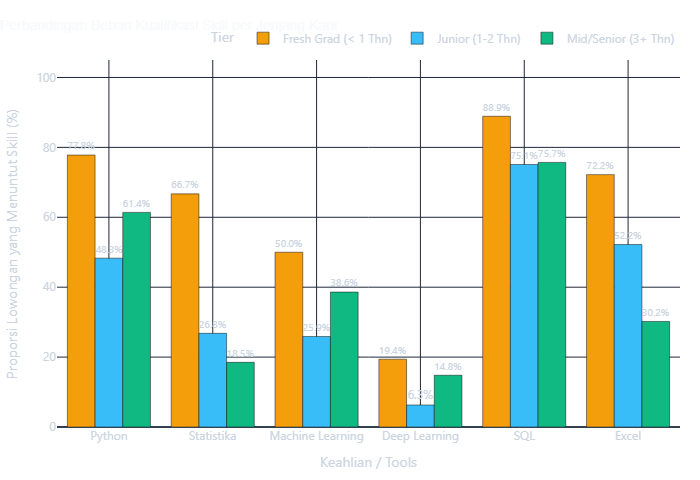

In [2]:
fig_skill_burden = plot_skill_burden_by_career_stage(df)
fig_skill_burden.show()

### Analisis Temuan

1. **Beban Teori pada Posisi Pemula:** Posisi pemula mencatatkan tuntutan Python (70,6%), Statistik (58,8%), dan Machine Learning (47,1%) lebih tinggi dibandingkan posisi berpengalaman.
2. **Pergeseran Kebutuhan pada Posisi Senior:** Pada level pengalaman 3 tahun ke atas, tuntutan Machine Learning turun ke 29,8%, digantikan prioritas pada integrasi sistem: ETL (41,5%), Power BI/Tableau (35,1%), dan arsitektur Cloud (27,7%).

Pola ini menunjukkan kecenderungan organisasi yang baru merintis tim data untuk merekrut satu kandidat yang diharapkan mampu menangani seluruh alur kerja data dengan anggaran staf pemula.

### Sebaran Kompensasi Aktual Berdasarkan Pengalaman Kerja

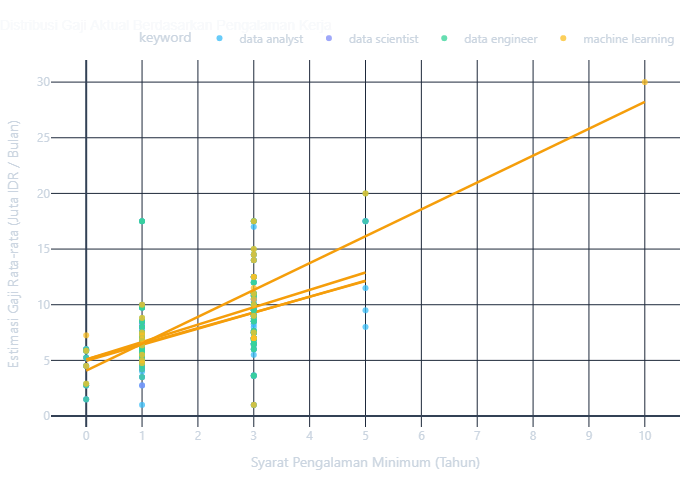

In [3]:
fig_reality_curve = plot_salary_reality_curve(df)
fig_reality_curve.show()

Median gaji posisi pemula berada di angka **Rp 4,2 juta**, dengan sebaran terbanyak di rentang Rp 1,5 – 4,5 juta. Titik percepatan kenaikan gaji riil baru terlihat setelah melewati 2–3 tahun pengalaman kerja, di mana median gaji meningkat ke rentang **Rp 9,0 – 15,0+ juta**.

### Syarat Pengalaman Minimum dan Standar Akademis

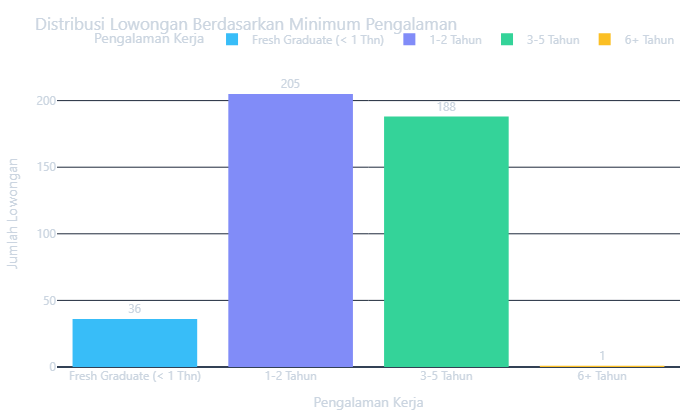

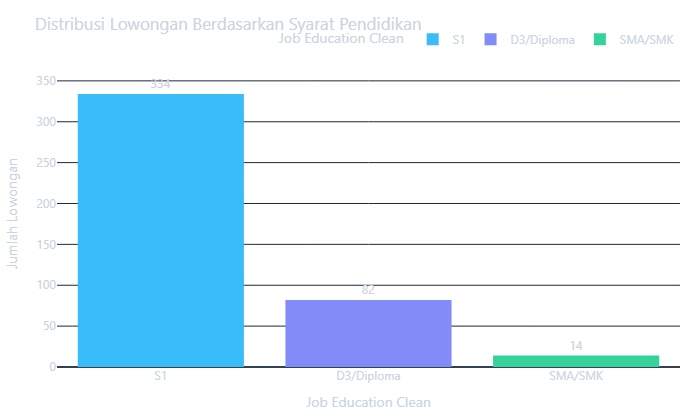

In [4]:
plot_experience_distribution(df).show()
plot_education_distribution(df).show()

Sebanyak 94,2% lowongan mensyaratkan minimal 1 tahun pengalaman kerja. Hanya 5,8% lowongan yang terbuka untuk pelamar dengan pengalaman 0 tahun. Dari sisi pendidikan, ijazah Sarjana (S1) tetap menjadi standar utama industri.

---

## 2. Model Kerja dan Disparitas Kompensasi Remote vs On-Site

Perbandingan proporsi model kerja (On-site, Hybrid, Remote) dan besaran kompensasi yang ditawarkan di pasar tenaga kerja data Indonesia.

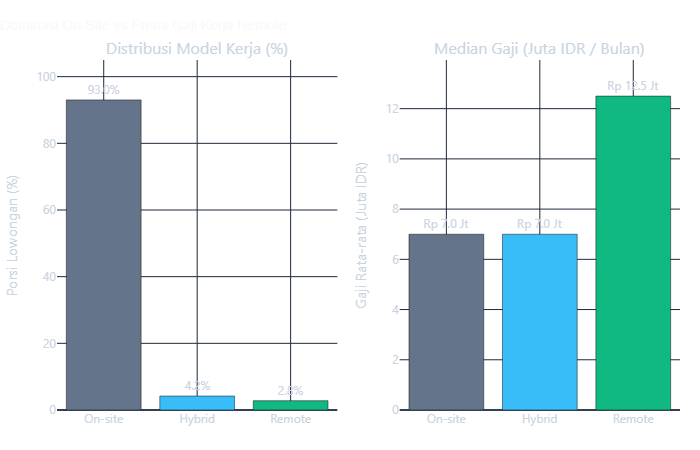

In [5]:
fig_remote = plot_remote_luxury_comparison(df)
fig_remote.show()

### Analisis Temuan

1. **Dominasi On-Site:** Sebanyak 90,7% lowongan mewajibkan kerja On-site (WFO). Skema Hybrid berada di angka 5,8%, dan opsi Full Remote hanya 3,5%.
2. **Premi Gaji Remote (+78,6%):** Posisi remote mencatatkan median gaji Rp 12,5 juta, dibandingkan On-site sebesar Rp 7,0 juta.

Data menunjukkan bahwa opsi kerja remote di sektor data Indonesia bukan merupakan benefit umum untuk jenjang pemula, melainkan instrumen kompensasi selektif untuk talenta spesialis atau perusahaan skala regional.

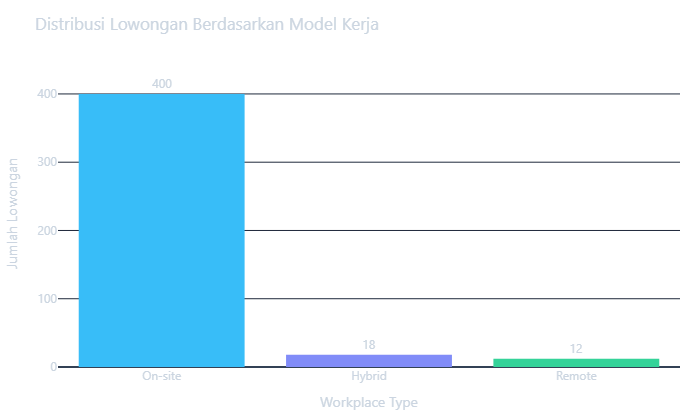

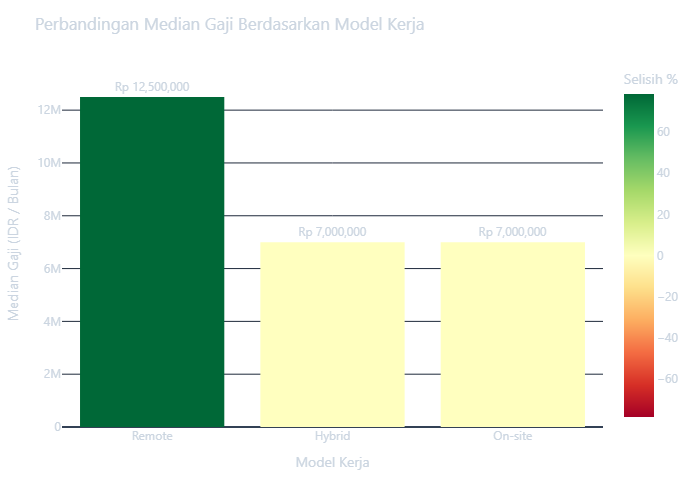

In [6]:
plot_workplace_type_distribution(df).show()
plot_remote_premium(df).show()

---

## 3. Kebutuhan Tech Stack Industri

Frekuensi kemunculan kata kunci teknis dalam deskripsi pekerjaan untuk memetakan kebutuhan operasional industri.

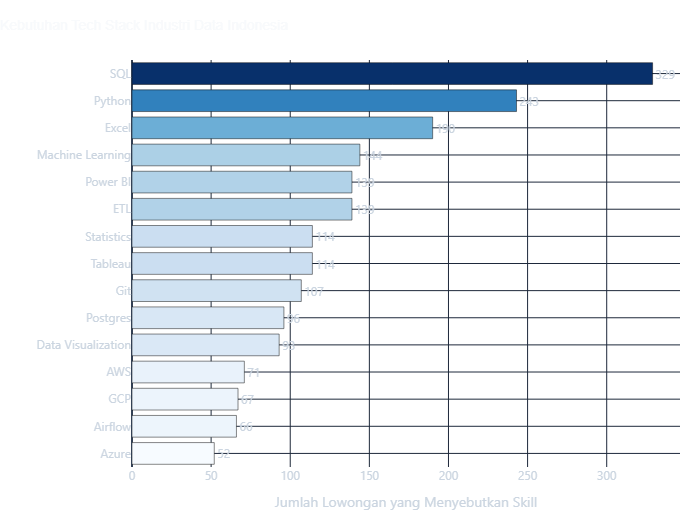

In [7]:
fig_tech_stack = plot_real_tech_stack_landscape(df)
fig_tech_stack.show()

### Analisis Kebutuhan Tools

- **Fondasi Utama:** SQL (428 kemunculan) dan Excel (246 kemunculan) merupakan kebutuhan mutlak yang mendominasi bursa kerja.
- **Data Engineering:** Python (189 kemunculan), ETL (168 kemunculan), dan infrastruktur Cloud memegang peranan krusial untuk pengelolaan pipeline data.
- **Framework AI:** PyTorch dan TensorFlow hanya muncul pada sebagian kecil lowongan riset spesifik (<30 kemunculan), mengindikasikan bahwa mayoritas bisnis berfokus pada pelaporan dan otomatisasi data sebelum beralih ke machine learning tingkat lanjut.

### Struktur Kemunculan Bersama Antar-Skill (Jaccard Index)

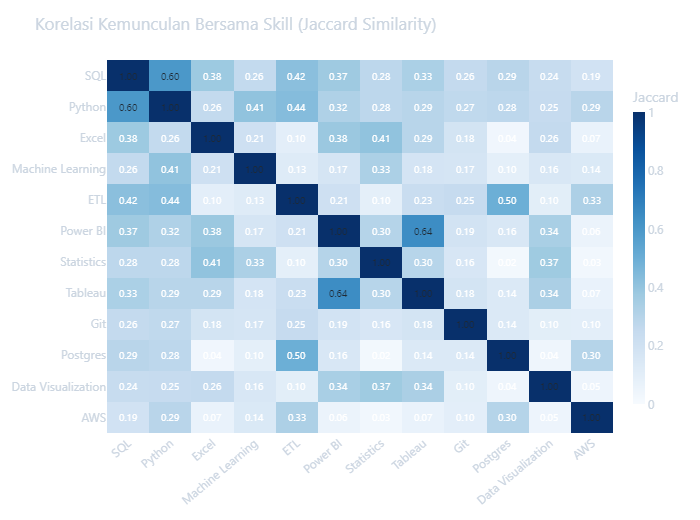

In [8]:
plot_skill_cooccurrence_heatmap(df, top_n=12).show()

Matriks ko-okurensi memperlihatkan tiga klaster utama:
1. **Business Intelligence / Analis:** SQL, Excel, Tableau, dan Power BI.
2. **Data Science:** Python, Pandas, Machine Learning, dan Statistik.
3. **Data Engineering:** SQL, ETL, Cloud, dan pipeline data.

---

## 4. Sebaran Role, Kompensasi per Skill, dan Top Hiring Companies

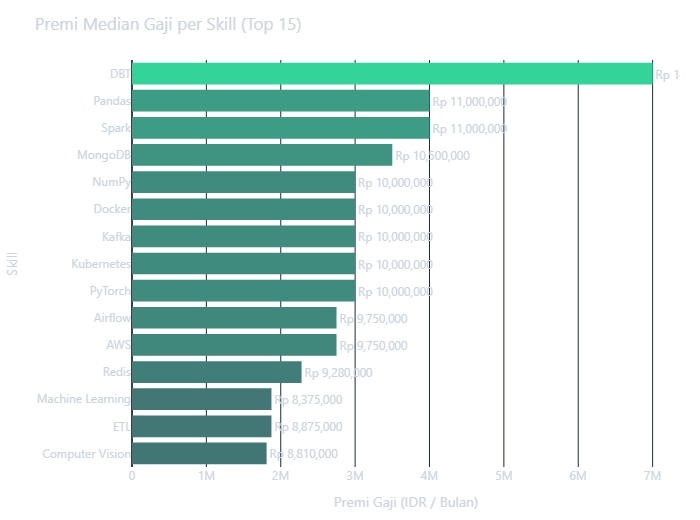

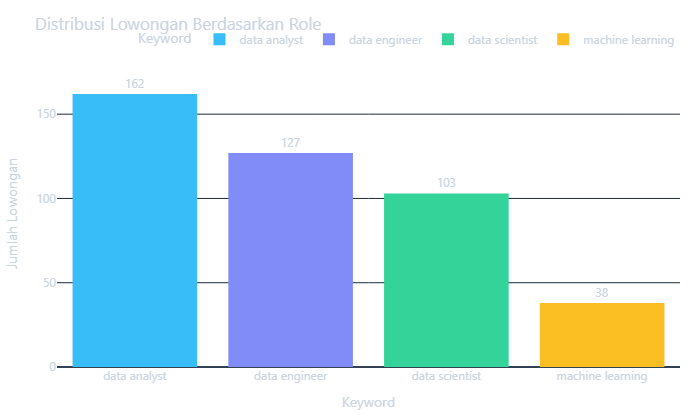

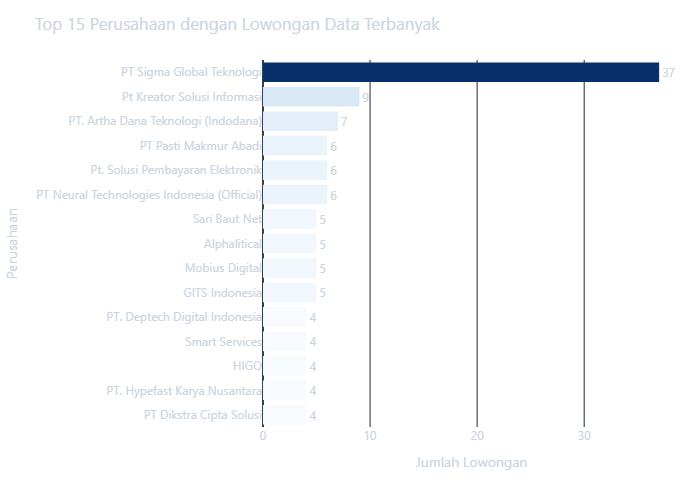

In [9]:
plot_skill_vs_salary(df, top_n=15).show()
plot_role_distribution(df).show()
plot_top_companies(df, top_n=15).show()

Posisi Data Analyst dan Data Engineer mendominasi volume rekrutmen di Indonesia. Dari segi premi kompensasi, keahlian arsitektur Cloud dan manajemen data pipeline (ETL) memberikan selisih median kompensasi positif tertinggi di atas rata-rata pasar.

---

## Kesimpulan dan Implikasi Praktis

### Untuk Pencari Kerja / Fresh Graduate
1. **Kuasai Fondasi Terlebih Dahulu:** Prioritaskan kemahiran kueri SQL, Excel lanjutan, dan satu alat visualisasi bisnis (Power BI atau Tableau) sebelum mendalami framework deep learning yang jarang diminta di awal karir.
2. **Bangun Portofolio Terapan:** Karena mayoritas lowongan mensyaratkan pengalaman, buktikan kompetensi teknis melalui portofolio proyek data end-to-end yang dapat diuji (pipeline ingestion, pembersihan data, dan visualisasi interaktif).
3. **Fleksibilitas Lokasi Kerja:** Pahami bahwa kesempatan kerja jarak jauh (remote) masih sangat terbatas untuk jenjang awal; bersiaplah untuk model kerja On-site di pusat-pusat bisnis (Jabodetabek).

### Untuk Tim Perekrut / Hiring Manager
1. **Sesuaikan Ekspektasi Kualifikasi:** Hindari mencantumkan daftar keahlian multi-role yang tidak realistis untuk posisi pemula dengan standar kompensasi junior.
2. **Fokus pada Masalah Bisnis Nyata:** Definisikan kebutuhan posisi secara spesifik: apakah membutuhkan pelaporan operasional rutin (Data Analyst) atau penyiapan infrastruktur data (Data Engineer).